### EXPERIMENT 1: 1D CONVOLUTION AND CORRELATION

Objective: Understand kernel flipping in discrete convolution.

Tasks:
 1. Compute the full convolution and correlation.
 2. Compare their numerical outputs.
 3. Examine the effect of reversing the kernel.

Question: Why do convolution and correlation produce different results?

Input A:      [0 1 2 3 2 1 0]
Kernel B:     [ 1  3 -1]
Flipped B:    [-1  3  1]
Convolution:  [ 1  5  8  9  4  1 -1]
Correlation:  [-1  1  4  9  8  5  1]


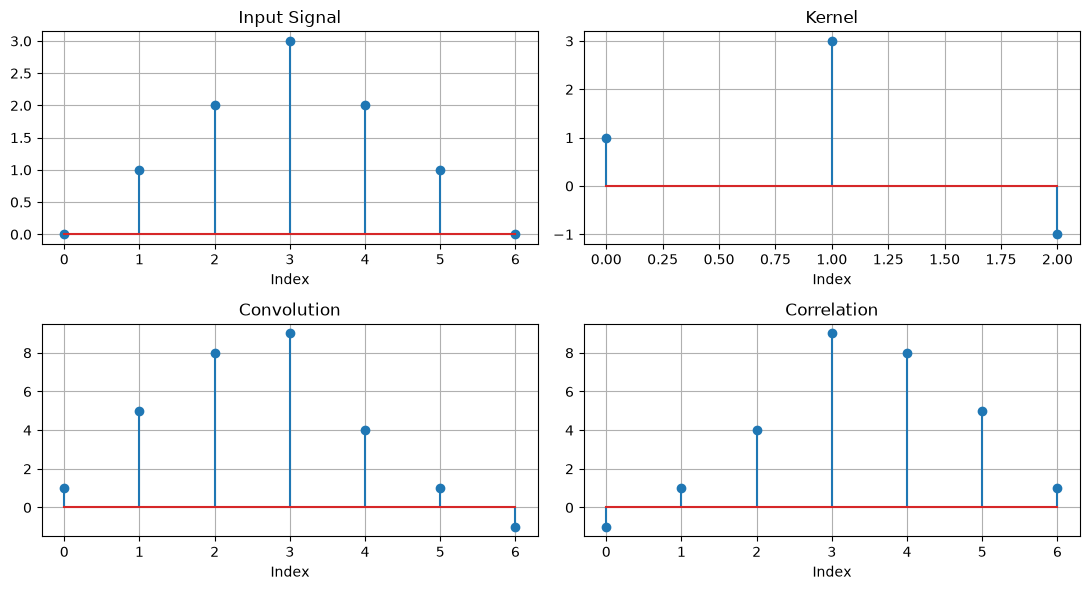

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve, correlate

A = np.array([0, 1, 2, 3, 2, 1, 0])
B = np.array([1, 3, -1])

conv = convolve(A, B, mode="same")
corr = correlate(A, B, mode="same")

print("Input A:     ", A)
print("Kernel B:    ", B)
print("Flipped B:   ", B[::-1])
print("Convolution: ", conv)
print("Correlation: ", corr)

fig, axes = plt.subplots(2, 2, figsize=(11, 6))

for ax, values, title in zip(
    axes.flat,
    [A, B, conv, corr],
    ["Input Signal", "Kernel", "Convolution", "Correlation"]
):
    ax.stem(np.arange(len(values)), values)
    ax.set_title(title)
    ax.set_xlabel("Index")
    ax.grid(True)

plt.tight_layout()
plt.show()

### EXPERIMENT 2: 2D CONVOLUTION FROM SCRATCH

Objective: Implement convolution using a sliding 3×3 kernel.

Tasks:
 1. Flip the kernel horizontally and vertically.
 2. Extract each 3×3 neighborhood.
 3. Compute the sum of elementwise products.
 4. Compare with scipy.signal.convolve2d().

Question: Why must the kernel be flipped during convolution?

Manual convolution:
 [[ 20.  10.   2.  26.  11.]
 [ 18.   1.  -8.   2.  -6.]
 [ 14.  22.   5.  -1. -13.]
 [ 29.  21.   9.  -9.  -7.]
 [ 12.  -3.  -1. -17. -13.]]

SciPy convolution:
 [[ 20  10   2  26  11]
 [ 18   1  -8   2  -6]
 [ 14  22   5  -1 -13]
 [ 29  21   9  -9  -7]
 [ 12  -3  -1 -17 -13]]

Results match: True


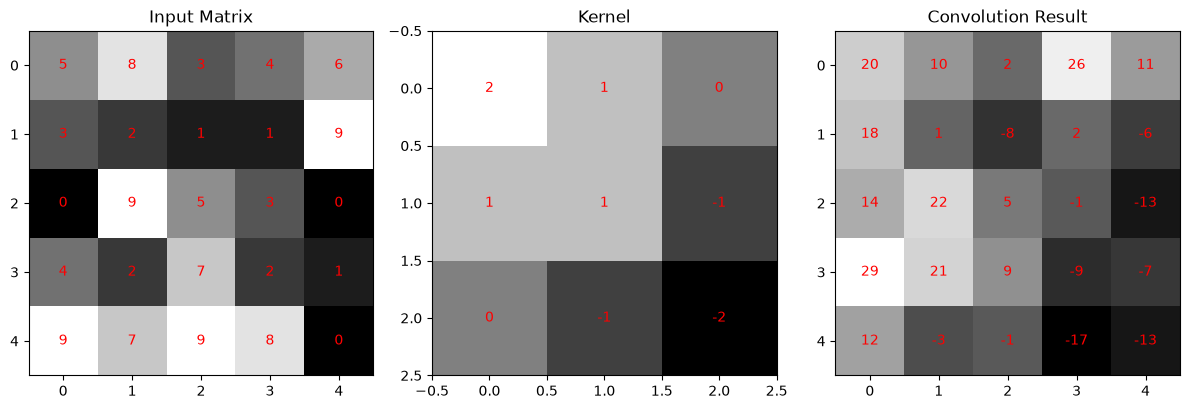

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

A = np.array([
    [5, 8, 3, 4, 6],
    [3, 2, 1, 1, 9],
    [0, 9, 5, 3, 0],
    [4, 2, 7, 2, 1],
    [9, 7, 9, 8, 0]
])

B = np.array([
    [ 2,  1,  0],
    [ 1,  1, -1],
    [ 0, -1, -2]
])

# Flip kernel for convolution
K = np.flip(B)

# Zero padding
padded = np.pad(A, 1, mode="constant")
output = np.zeros_like(A, dtype=float)

for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        neighborhood = padded[i:i+3, j:j+3]
        output[i, j] = np.sum(neighborhood * K)

reference = convolve2d(A, B, mode="same", boundary="fill")

print("Manual convolution:\n", output)
print("\nSciPy convolution:\n", reference)
print("\nResults match:", np.allclose(output, reference))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, matrix, title in zip(
    axes,
    [A, B, output],
    ["Input Matrix", "Kernel", "Convolution Result"]
):
    ax.imshow(matrix, cmap="gray")
    ax.set_title(title)

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, f"{matrix[i, j]:.0f}",
                    ha="center", va="center", color="red")

plt.tight_layout()
plt.show()

### EXPERIMENT 3: CONVOLUTION VERSUS CORRELATION

Objective: Compare convolution and correlation using different kernels.

Tasks:
 1. Apply a symmetric kernel.
 2. Apply an asymmetric kernel.
 3. Compare the numerical outputs.

Question: Under what condition are convolution and correlation identical?


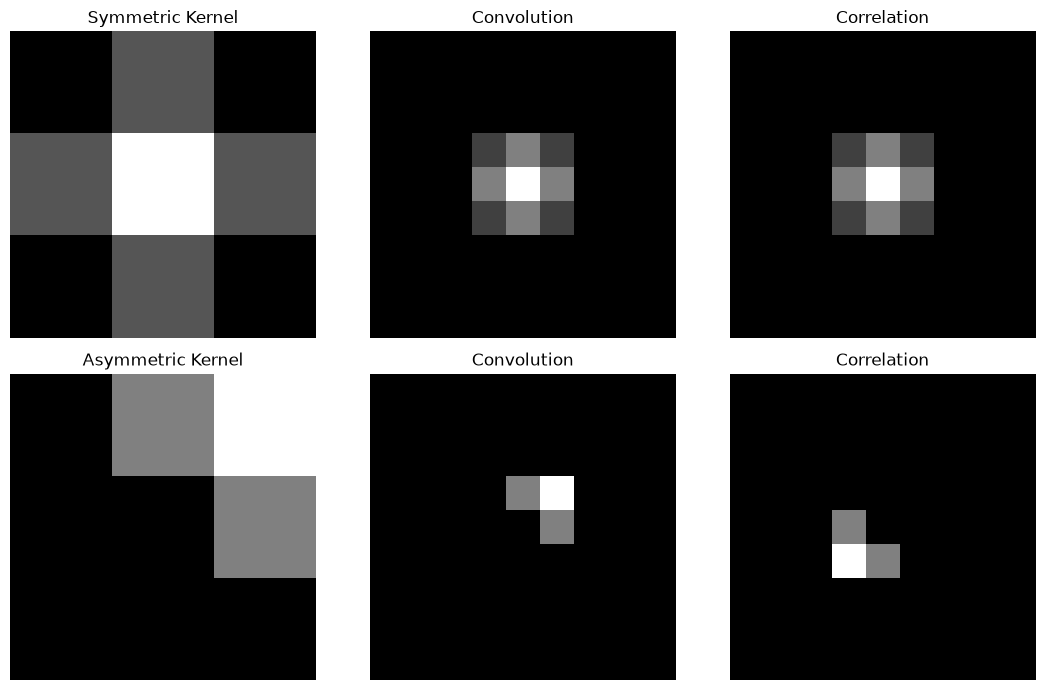

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve, correlate

img = np.zeros((9, 9))
img[4, 4] = 1

symmetric = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
]) / 16

asymmetric = np.array([
    [0, 1, 2],
    [0, 0, 1],
    [0, 0, 0]
])

fig, axes = plt.subplots(2, 3, figsize=(11, 7))

for row, (kernel, name) in enumerate([
    (symmetric, "Symmetric"),
    (asymmetric, "Asymmetric")
]):
    images = [
        kernel,
        convolve(img, kernel, mode="constant"),
        correlate(img, kernel, mode="constant")
    ]

    titles = [
        f"{name} Kernel",
        "Convolution",
        "Correlation"
    ]

    for ax, image, title in zip(axes[row], images, titles):
        ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 4: BORDER HANDLING

Objective: Investigate different boundary extension strategies.

Tasks:
 1. Apply the same mean filter using four boundary modes.
 2. Compare their effects near image borders.
 3. Identify which modes introduce artificial boundary values.

Question: Why can zero padding produce dark borders?

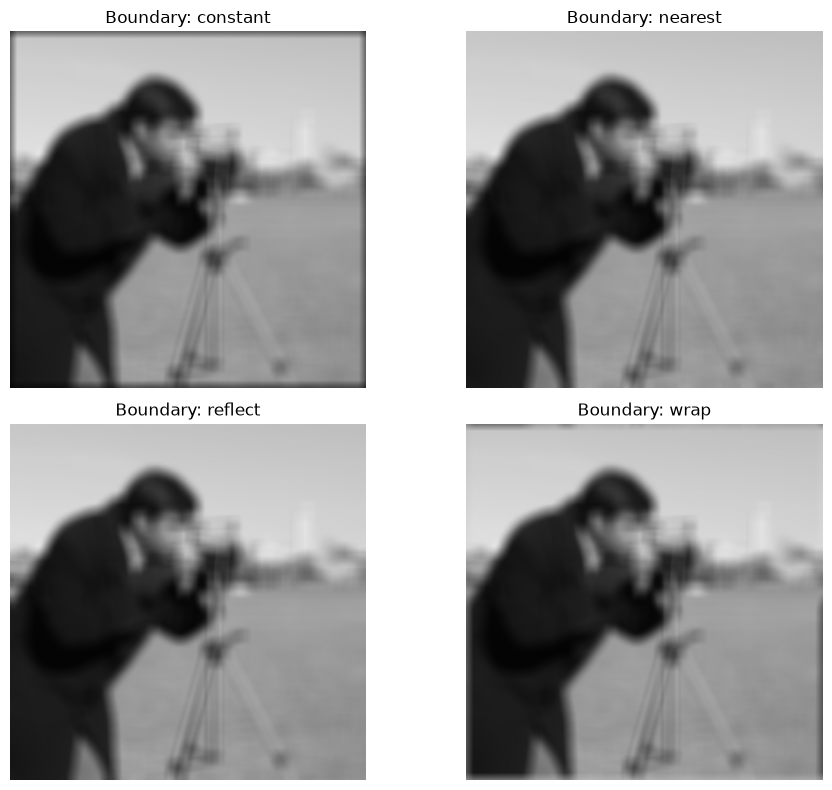

In [ ]:
from skimage import data
from scipy.ndimage import uniform_filter
import matplotlib.pyplot as plt

img = data.camera().astype(float)

modes = ["constant", "nearest", "reflect", "wrap"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, mode in zip(axes.flat, modes):
    filtered = uniform_filter(img, size=21, mode=mode)

    ax.imshow(filtered, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Boundary: {mode}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 5: PIXEL NEIGHBORHOODS

Objective: Visualize 4-neighborhood, diagonal, and 8-neighborhood connectivity.

Tasks:
 1. Define the reference pixel.
 2. Identify its four orthogonal neighbors.
 3. Identify its diagonal and eight-connected neighbors.

Question: How does 4-connectivity differ from 8-connectivity?

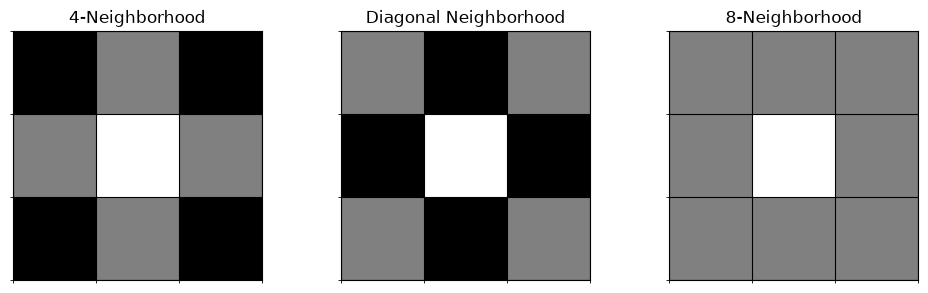

In [6]:
import numpy as np
import matplotlib.pyplot as plt

N4 = np.array([
    [0, 1, 0],
    [1, 2, 1],
    [0, 1, 0]
])

ND = np.array([
    [1, 0, 1],
    [0, 2, 0],
    [1, 0, 1]
])

N8 = np.array([
    [1, 1, 1],
    [1, 2, 1],
    [1, 1, 1]
])

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for ax, matrix, title in zip(
    axes,
    [N4, ND, N8],
    ["4-Neighborhood", "Diagonal Neighborhood", "8-Neighborhood"]
):
    ax.imshow(matrix, cmap="gray", vmin=0, vmax=2)
    ax.set_title(title)
    ax.set_xticks(np.arange(-0.5, 3, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 3, 1), minor=True)
    ax.grid(which="minor", color="black")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

### EXPERIMENT 6: LINEAR LOW-PASS FILTERING

Objective: Compare mean and Gaussian smoothing.

Tasks:
 1. Add Gaussian noise to an image.
 2. Apply mean and Gaussian filters.
 3. Compare noise suppression and detail preservation.

Question: How does Gaussian smoothing differ from uniform averaging?

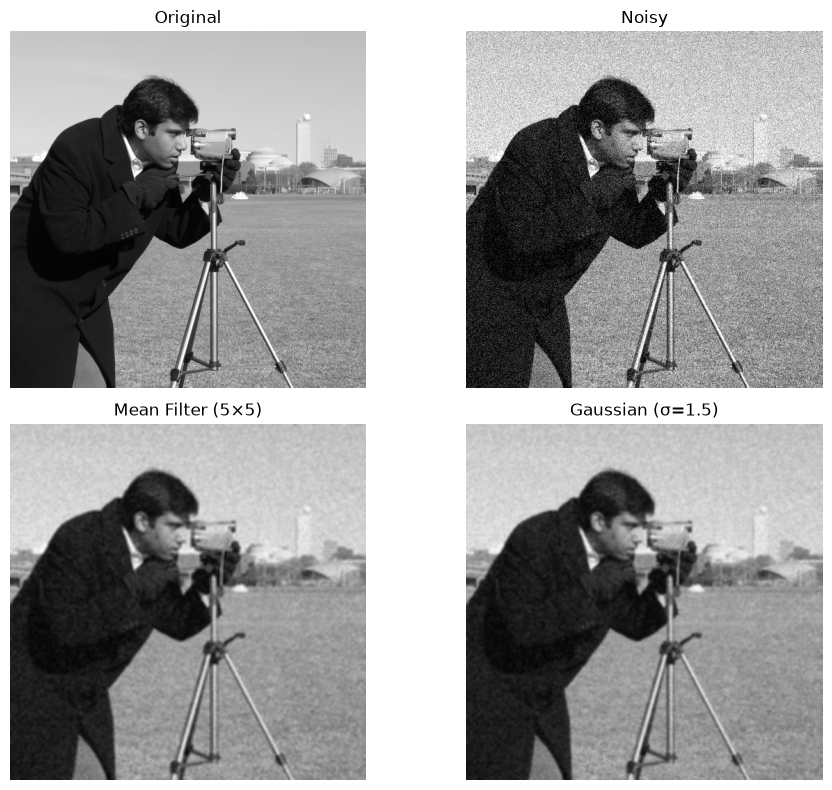

In [8]:
from skimage import data
from scipy.ndimage import uniform_filter, gaussian_filter
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

rng = np.random.default_rng(42)
noisy = np.clip(img + rng.normal(0, 25, img.shape), 0, 255)

mean = uniform_filter(noisy, size=5)
gaussian = gaussian_filter(noisy, sigma=1.5)

images = [img, noisy, mean, gaussian]
titles = ["Original", "Noisy", "Mean Filter (5×5)", "Gaussian (σ=1.5)"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 7: LINEAR HIGH-PASS FILTERING

Objective: Investigate Laplacian filtering and image sharpening.

Tasks:
 1. Apply 4-neighbor and 8-neighbor Laplacian kernels.
 2. Compare their responses to intensity transitions.
 3. Sharpen the original image using a Laplacian response.

Question: Why does the Laplacian emphasize edges and fine details?

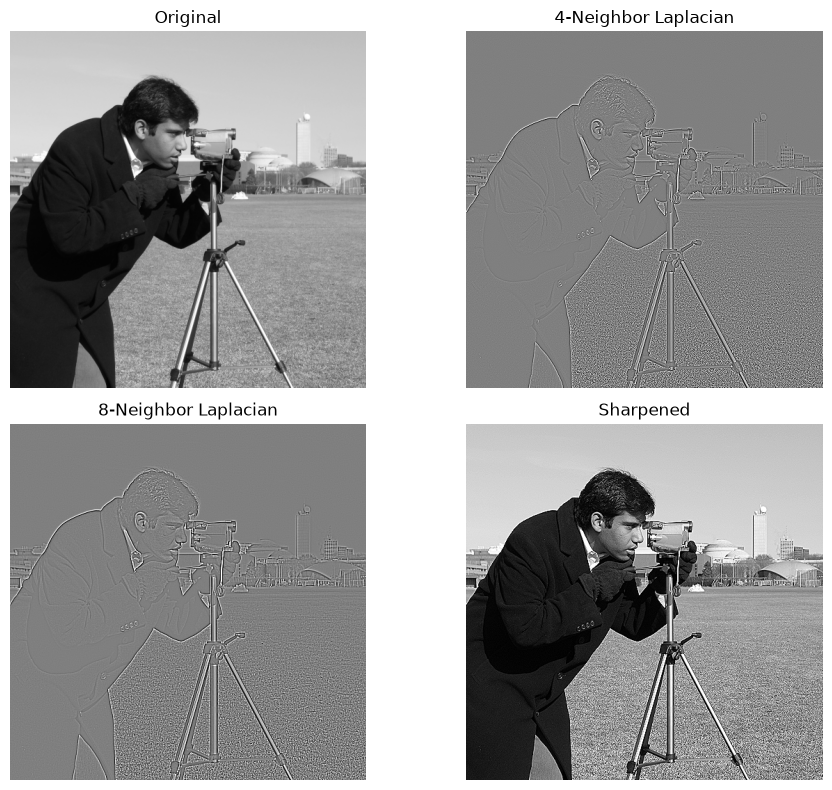

In [9]:
from skimage import data
from scipy.ndimage import convolve
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

lap4 = np.array([
    [ 0, -1,  0],
    [-1,  4, -1],
    [ 0, -1,  0]
])

lap8 = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

response4 = convolve(img, lap4, mode="reflect")
response8 = convolve(img, lap8, mode="reflect")

# Positive-center Laplacian: add the response for sharpening
sharpened = np.clip(img + response4, 0, 255)

images = [img, response4, response8, sharpened]
titles = ["Original", "4-Neighbor Laplacian",
          "8-Neighbor Laplacian", "Sharpened"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image, title in zip(axes.flat, images, titles):
    if "Laplacian" in title:
        limit = np.percentile(np.abs(image), 99)
        ax.imshow(image, cmap="gray", vmin=-limit, vmax=limit)
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 8: NONLINEAR SPATIAL FILTERING
Objective: Compare mean and median filtering for impulse noise.

Tasks:
 1. Introduce salt-and-pepper noise.
 2. Apply mean and median filters.
 3. Compare noise removal and edge preservation.

Question: Why is median filtering generally effective against impulse noise?


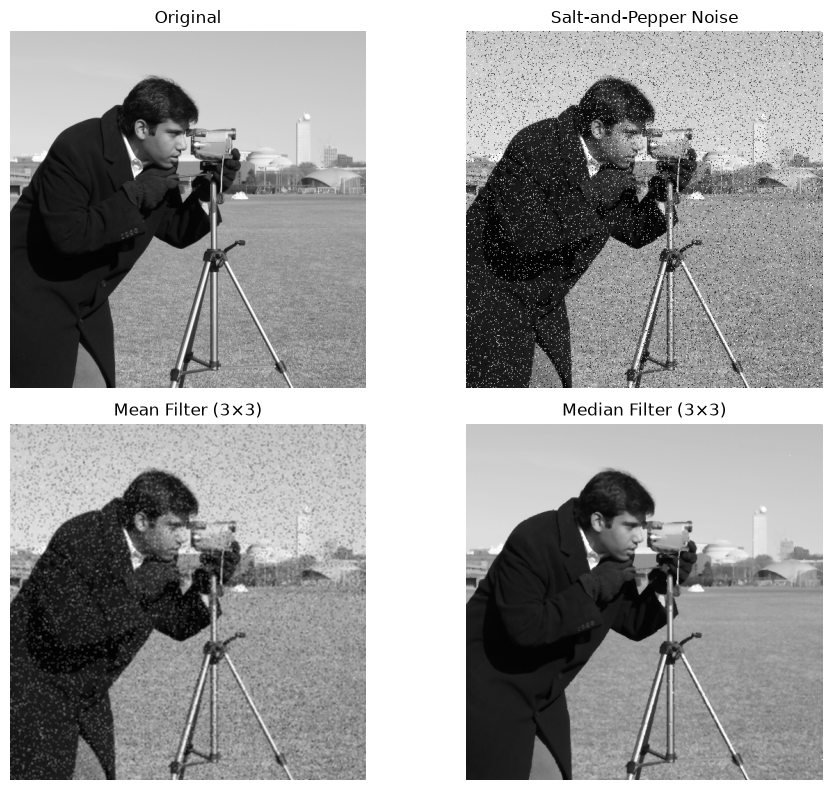

In [10]:

from skimage import data, util
from scipy.ndimage import uniform_filter, median_filter
import numpy as np
import matplotlib.pyplot as plt

img = data.camera()

noisy = util.random_noise(img, mode="s&p", amount=0.08)
noisy = (noisy * 255).astype(np.uint8)

mean = uniform_filter(noisy.astype(float), size=3)
median = median_filter(noisy, size=3)

images = [img, noisy, mean, median]
titles = ["Original", "Salt-and-Pepper Noise",
          "Mean Filter (3×3)", "Median Filter (3×3)"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()